# LEXICON-X II — Echoes of Eráviri | Notebook del equipo
Examen final NLP · Maestría en Informática

**Estructura:** 0. Configuración y reproducibilidad · 1. Exploración · 2. Hipótesis · 3. Baseline · 4. Alternativa · 5. Robustez · 6. Análisis de errores · 7. Reproducibilidad

Los CSV deben estar en la misma carpeta que este notebook (en Colab: subir y extraer el ZIP en `/content`).

## 0. Configuración y reproducibilidad

In [1]:
import sys, platform, random, re, time
import numpy as np, pandas as pd, sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)
print('Python', sys.version.split()[0], '|', platform.platform())
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__, '| SEED', SEED)

D  = pd.read_csv('corpus_documentos.csv')
T  = pd.read_csv('train_qa.csv', dtype={'answer': str}).fillna('')
V  = pd.read_csv('validation_qa.csv', dtype={'answer': str}).fillna('')
LX = pd.read_csv('lexico.csv')
print(D.shape, T.shape, V.shape, LX.shape)

Python 3.13.18 | Linux-6.18.44-fc-v880-x86_64-with-glibc2.39
pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | SEED 42
(1500, 8) (500, 5) (150, 5) (6, 2)


In [2]:
def evaluate(pred, gold):
    assert pred.qid.is_unique and set(pred.qid) == set(gold.qid), 'IDs incompletos o duplicados'
    z = gold.merge(pred, on='qid', suffixes=('_gold', '_pred'))
    exact = (z.answer_gold.astype(str).str.strip().str.lower() == z.answer_pred.astype(str).str.strip().str.lower())
    def hit(r):
        g = set(str(r.evidence_ids).split('|')) - {'', 'nan'}; p = set(str(r.citations).split('|')) - {'', 'nan'}
        return bool(g & p) if g else not p
    h = z.apply(hit, axis=1)
    return {'EM': float(exact.mean()), 'evidence_hit': float(h.mean()), 'joint': float((exact & h).mean()),
            'by_kind': exact.groupby(z.kind).mean().to_dict()}

## 1. Exploración del corpus y de las preguntas
### 1.1 Composición del corpus

In [3]:
display(D.head(6))
print(D.groupby(['language', 'source', 'year', 'reliability']).size().rename('docs'))
print('\nSitios:', D.site.nunique(), '| temas:', D.topic.value_counts().to_dict())

,doc_id,site,topic,language,year,source,reliability,text
0,D000-0,ER-000,agricultura,es,2048,oficial,0.95,El registro oficial de ER-000 confirma 93 semillas disponibles.
1,D000-1,ER-000,agricultura,er,2048,oficial,0.95,ER-000 sava 93 ena.
2,D000-2,ER-000,agricultura,es,2047,oficial,0.90,El registro anterior de ER-000 indica 100 semillas disponibles.
3,D000-3,ER-000,agricultura,er,2047,oficial,0.90,ER-000 sava 100 ena.
4,D000-4,ER-000,agricultura,es,2048,rumor,0.20,Un rumor sobre ER-000 menciona 112 semillas disponibles.
5,D000-5,ER-000,agricultura,es,2048,archivo,0.70,"El archivo de ER-000 registra actividades de agricultura, sin inventario adicional."


language  source   year  reliability
er        oficial  2047  0.90           250
                   2048  0.95           250
es        archivo  2048  0.70           250
          oficial  2047  0.90           250
                   2048  0.95           250
          rumor    2048  0.20           250
Name: docs, dtype: int64

Sitios: 250 | temas: {'agricultura': 300, 'energía': 300, 'transporte': 300, 'archivo': 300, 'agua': 300}


Cada sitio tiene **exactamente 6 documentos**, siempre en el mismo orden (sufijo del `doc_id`):

| sufijo | idioma | fuente | año | confiab. | contenido |
|---|---|---|---|---|---|
| -0 | es | oficial | 2048 | 0.95 | valor vigente |
| -1 | er | oficial | 2048 | 0.95 | traducción Eráviri de -0 |
| -2 | es | oficial | 2047 | 0.90 | valor histórico |
| -3 | er | oficial | 2047 | 0.90 | traducción Eráviri de -2 |
| -4 | es | rumor | 2048 | 0.20 | valor contradictorio |
| -5 | es | archivo | 2048 | 0.70 | distractor sin número |

Lo verificamos abajo en lugar de suponerlo.

In [4]:
D['slot'] = D.doc_id.str.split('-').str[1].astype(int)
print(D.groupby(['slot', 'language', 'source', 'year', 'reliability']).size().rename('docs'))

def plantilla(s):
    s = re.sub(r'ER-\d+', 'ER-X', s); s = re.sub(r'\b\d+\b', 'N', s)
    return re.sub(r'(celdas|depósitos|semillas|tablillas|vehículos)', 'OBJ', s)
print('\nPlantillas de texto por slot:')
print(D.assign(t=D.text.map(plantilla)).groupby(['slot', 't']).size().to_string())

slot  language  source   year  reliability
0     es        oficial  2048  0.95           250
1     er        oficial  2048  0.95           250
2     es        oficial  2047  0.90           250
3     er        oficial  2047  0.90           250
4     es        rumor    2048  0.20           250
5     es        archivo  2048  0.70           250
Name: docs, dtype: int64

Plantillas de texto por slot:
slot  t                                                                                
0     El registro oficial de ER-X confirma N OBJ disponibles.                              250
1     ER-X kiri N ena.                                                                      50
      ER-X mura N ena.                                                                      50
      ER-X nora N ena.                                                                      50
      ER-X sava N ena.                                                                      50
      ER-X tavi N ena.                

### 1.2 Léxico Eráviri–español

In [5]:
display(LX)
OBJ = ['celdas', 'depósitos', 'semillas', 'tablillas', 'vehículos']
D['obj'] = D.text.str.extract('(' + '|'.join(OBJ) + ')', expand=False)
print(pd.crosstab(D.topic, D.obj))  # cada tema tiene un único objeto
# ¿Los documentos Eráviri usan solo palabras del léxico?
er_vocab = set(w for t in D[D.language == 'er'].text for w in re.findall(r'[a-záéíóú]+', t.lower()) if w != 'er')
print('Vocabulario Eráviri del corpus:', sorted(er_vocab), '| cubierto por léxico:', er_vocab <= set(LX.er))

,er,es
0,sava,semillas
1,tavi,celdas
2,nora,vehículos
3,kiri,tablillas
4,mura,depósitos
5,ena,disponibles


obj          celdas  depósitos  semillas  tablillas  vehículos
topic                                                         
agricultura       0          0       150          0          0
agua              0        150         0          0          0
archivo           0          0         0        150          0
energía         150          0         0          0          0
transporte        0          0         0          0        150
Vocabulario Eráviri del corpus: ['ena', 'kiri', 'mura', 'nora', 'sava', 'tavi'] | cubierto por léxico: True


### 1.3 Consistencia y contradicciones entre fuentes

In [6]:
num = lambda t: int(re.findall(r'\b\d+\b', re.sub(r'ER-\d+', '', t))[0]) if re.findall(r'\b\d+\b', re.sub(r'ER-\d+', '', t)) else np.nan
D['num'] = D.text.map(num)
P = D.pivot(index='site', columns='slot', values='num')
print('es == er (2048):', (P[0] == P[1]).mean(), '| es == er (2047):', (P[2] == P[3]).mean())
print('rumor == vigente:', (P[4] == P[0]).mean(), '| 2047 == 2048:', (P[2] == P[0]).mean())
print('archivo sin número:', P[5].isna().mean())
print('\nrumor − vigente:', (P[4] - P[0]).describe()[['mean', 'std']].to_dict(),
      '| 2047 − 2048:', (P[2] - P[0]).describe()[['mean', 'std']].to_dict())

es == er (2048): 1.0 | es == er (2047): 1.0
rumor == vigente: 0.0 | 2047 == 2048: 0.0
archivo sin número: 1.0

rumor − vigente: {'mean': 19.0, 'std': 0.0} | 2047 − 2048: {'mean': 7.0, 'std': 0.0}


> **Observación:** el rumor siempre difiere del oficial (contradicción en 100% de los sitios) y la traducción Eráviri siempre coincide con el español. Las diferencias son constantes (+19 rumor, +7 histórico): es un artefacto del generador sintético. **No lo explotamos** (sería sobreajustar al generador, no razonar con evidencia); solo lo documentamos.

### 1.4 Preguntas: tipos, plantillas y partición

In [7]:
for n, Q in [('train', T), ('validation', V)]:
    print(f'--- {n}:', Q.kind.value_counts().to_dict())
    print(Q.assign(t=Q.question.map(plantilla).str.replace(r'\b\d{4}\b', 'AAAA', regex=True))
           .groupby(['kind', 't']).size().to_string())
site_of = lambda Q: set(Q.qid.str[1:4])
print('\nSitios train:', len(site_of(T)), '| val:', len(site_of(V)), '| solapamiento:', len(site_of(T) & site_of(V)))
print('Años pedidos en históricas:', sorted(set(T.question.str.extract(r'en (\d{4})')[0].dropna()) | set(V.question.str.extract(r'en (\d{4})')[0].dropna())))
ev_slots = T.evidence_ids.str.findall(r'-(\d)').map(lambda x: '|'.join(x))
print('\nSlots de evidencia gold por tipo (train):'); print(pd.crosstab(T.kind, ev_slots))

--- train: {'actual': 250, 'historico': 125, 'sin_evidencia': 125}
kind           t                                                         
actual         Según el registro vigente, ¿cuál es el inventario de ER-X?    125
               ¿Cuántas OBJ hay disponibles actualmente en ER-X?             125
historico      ¿Qué cantidad de OBJ registraba ER-X en N?                    125
sin_evidencia  ¿Quién dirige ER-X?                                           125
--- validation: {'actual': 74, 'historico': 41, 'sin_evidencia': 35}
kind           t                                                         
actual         Según el registro vigente, ¿cuál es el inventario de ER-X?    37
               ¿Cuántas OBJ hay disponibles actualmente en ER-X?             37
historico      ¿Qué cantidad de OBJ registraba ER-X en N?                    41
sin_evidencia  ¿Quién dirige ER-X?                                           35

Sitios train: 125 | val: 50 | solapamiento: 0
Años pedidos en histórica

> **Observación:** 4 plantillas de pregunta. La evidencia gold es siempre el par oficial es+er del año correcto (slots 0|1 para *actual*, 2|3 para *histórico*); *sin_evidencia* ("¿Quién dirige…?") no tiene documentos y debe responderse `SIN_EVIDENCIA` sin citas. La plantilla *"Según el registro vigente, ¿cuál es el inventario…?"* **no menciona el objeto**. Train y validación usan sitios disjuntos, así que reglas que dependan del sitio no generalizan.

### 1.5 Diagnóstico de la recuperación léxica (TF-IDF del notebook base)
Antes de formular la hipótesis medimos dónde falla el pipeline ingenuo *TF-IDF top-1 → primer número*, solo sobre **train**.

In [8]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2)); M = vectorizer.fit_transform(D.text.tolist())
print('Tokenización de un doc Eráviri:', vectorizer.build_analyzer()('ER-000 sava 93 ena.'))
LAB = {0: 'of2048_es', 1: 'of2048_er', 2: 'of2047_es', 3: 'of2047_er', 4: 'rumor', 5: 'archivo'}
tipo = lambda q: plantilla(q).replace('ER-X', '').split()[0] + ' ' + plantilla(q).split()[1]
rows = []
for _, q in T.iterrows():
    s = linear_kernel(vectorizer.transform([q.question]), M).ravel(); top = np.argsort(-s, kind='stable')[:5]
    g = set(q.evidence_ids.split('|')) - {''}; site = 'ER-' + q.qid[1:4]
    n0 = D.num.iloc[top[0]]
    rows.append(dict(kind=q.kind, plantilla=re.sub(r'\d{4}', 'AAAA', plantilla(q.question))[:45], top1=LAB[D.slot.iloc[top[0]]],
                     sitio_ok_top5=(D.site.iloc[top] == site).mean(), hit1=D.doc_id.iloc[top[0]] in g,
                     hit5=bool(g & set(D.doc_id.iloc[top])), em_naive=(str(int(n0)) if n0 == n0 else 'SIN_EVIDENCIA') == q.answer,
                     score1=s[top[0]]))
R = pd.DataFrame(rows)
display(R.groupby(['kind', 'plantilla'])[['sitio_ok_top5', 'hit1', 'hit5', 'em_naive', 'score1']].mean().round(3))
display(pd.crosstab([R.kind, R.plantilla], R.top1))
print('EM ingenuo global (train):', round(R.em_naive.mean(), 3))

Tokenización de un doc Eráviri: ['er', '000', 'sava', '93', 'ena', 'er 000', '000 sava', 'sava 93', '93 ena']


sitio_ok_top5   hit1  hit5  em_naive  score1
kind          plantilla                                                                                  
actual        Según el registro vigente, ¿cuál es el invent            1.0  0.000   1.0     0.000   0.549
              ¿Cuántas OBJ hay disponibles actualmente en E            1.0  0.488   1.0     0.488   0.532
historico     ¿Qué cantidad de OBJ registraba ER-X en N?               1.0  0.456   1.0     0.456   0.532
sin_evidencia ¿Quién dirige ER-X?                                      1.0  0.000   0.0     0.000   0.549

top1                                                         archivo  of2047_er  of2047_es  of2048_er  of2048_es  rumor
kind          plantilla                                                                                                
actual        Según el registro vigente, ¿cuál es el invent      125          0          0          0          0      0
              ¿Cuántas OBJ hay disponibles actualmente en E        0          0         55          0         61      9
historico     ¿Qué cantidad de OBJ registraba ER-X en N?           0          0         57          0         68      0
sin_evidencia ¿Quién dirige ER-X?                                  0         51          0         74          0      0

EM ingenuo global (train): 0.236


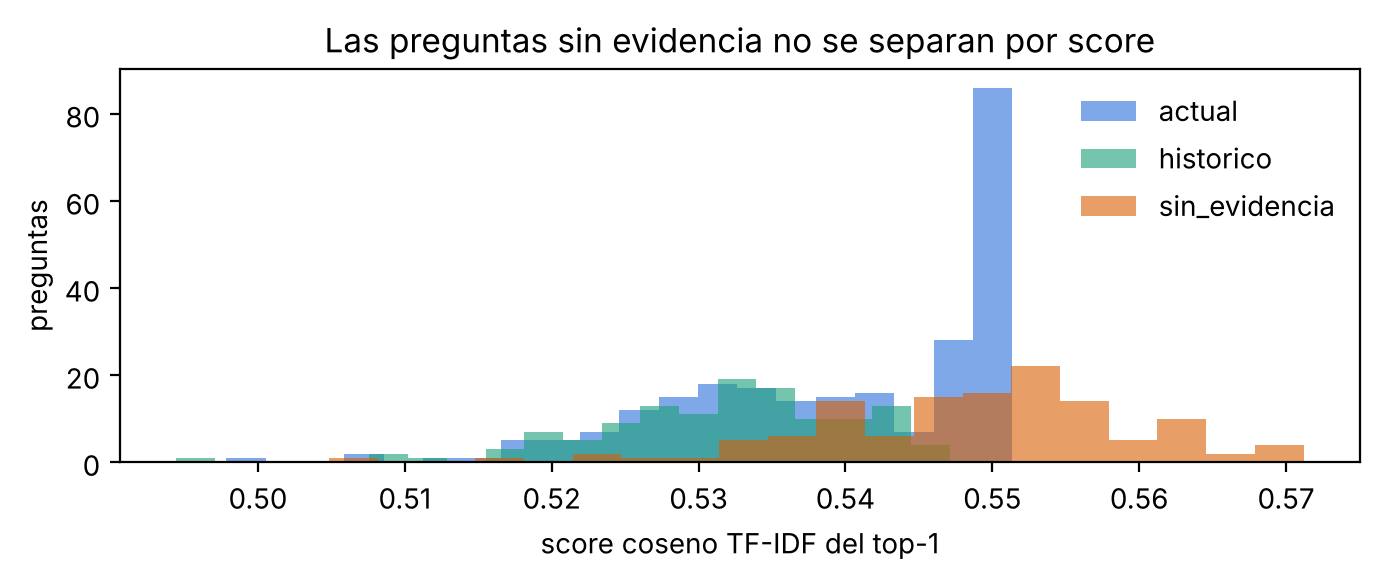

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
for k, c in zip(['actual', 'historico', 'sin_evidencia'], ['#2a6fdb', '#1a9e77', '#d95f02']):
    ax.hist(R[R.kind == k].score1, bins=20, alpha=.6, label=k, color=c)
ax.set_xlabel('score coseno TF-IDF del top-1'); ax.set_ylabel('preguntas'); ax.legend(frameon=False)
ax.set_title('Las preguntas sin evidencia no se separan por score'); plt.tight_layout(); plt.show()

### 1.6 Conclusiones de la exploración
1. **El sitio se recupera perfectamente:** el código `ER-XXX` domina el TF-IDF (100% de los top-5 son del sitio correcto). El problema no es *recall* sino **selección dentro del sitio**: el documento correcto siempre está en el top-5 (hit@5 = 1.0 para preguntas respondibles), pero el top-1 solo acierta ~47%.
2. **TF-IDF ignora tiempo y fuente:** para *"¿Cuántas … actualmente?"* el top-1 se reparte casi 50/50 entre 2048 y 2047 (las frases solo difieren en *confirma/oficial* vs *indica/anterior*), y a veces cae en el rumor. Para *"cuál es el inventario"* el top-1 es **siempre el archivo distractor** ("sin inventario adicional") → EM 0.
3. **La abstención no se puede decidir por umbral de similitud:** las preguntas *"¿Quién dirige…?"* obtienen scores iguales o mayores que las respondibles (comparten el código del sitio), y recuperan documentos Eráviri. Un sistema ingenuo siempre "inventa" un número.
4. **Contradicción sistemática:** cada sitio tiene un rumor que contradice al oficial; la metadata (`source`, `reliability`, `year`) es la única señal fiable para resolverla.
5. **Bilingüismo:** los documentos Eráviri son traducciones exactas del oficial español y el léxico cubre todo su vocabulario; son útiles como **evidencia corroborante** (cita adicional válida), no como fuente de información nueva.

## 2. Hipótesis (formulada antes de experimentar)

**Pregunta de investigación:** ¿Mejora la calidad de las respuestas con evidencia incorporar la metadata de los documentos (fuente, año, confiabilidad) y una verificación de respondibilidad, frente a la recuperación puramente léxica?

**H1 (principal, falsable).** Un sistema que (a) recupera candidatos por TF-IDF, (b) los **re-rankea con metadata** según la intención temporal de la pregunta (oficial + 2048 para *actual*; oficial + año pedido para *histórica*; penalizando rumores por confiabilidad) y (c) **se abstiene** cuando la pregunta no pide una cantidad de inventario, obtendrá en **validación** un **joint ≥ 0.90**, al menos **+40 puntos** sobre el baseline TF-IDF top-1 + extracción del primer número, con latencia media por pregunta **< 50 ms en CPU**.

- **Variable independiente:** estrategia de selección de evidencia (baseline léxico top-1 vs. alternativa léxico + re-ranking por metadata + verificador de respondibilidad).
- **Variables controladas:** mismo corpus, mismo vectorizador TF-IDF (1–2-gramas), mismas 150 preguntas de validación, mismo extractor numérico, misma función `evaluate`, semilla 42, CPU.
- **Variables dependientes (métricas):** EM, evidence_hit, joint (global y por `kind`), latencia media y p95 (ms/pregunta).
- **Criterio de éxito:** se acepta H1 si joint(alt) ≥ 0.90 **y** joint(alt) − joint(base) ≥ 0.40 en validación. **Se refuta** si la mejora es < 0.10 o si la alternativa empeora alguna categoría (`actual`, `historico`, `sin_evidencia`) respecto al baseline.

**H2 (secundaria).** La métrica sola de similitud no permite detectar ausencia de evidencia: un umbral sobre el score TF-IDF del top-1 elegido en train no supera un EM de 0.50 en `sin_evidencia` sin degradar las respondibles más de 10 puntos; un verificador por intención sí lo logra (EM `sin_evidencia` ≥ 0.95).

**H3 (robustez, exploratoria).** Citar el par bilingüe (es + er) no reduce evidence_hit respecto a citar solo el documento español, y evaluar con preguntas parafraseadas (p. ej. sin la palabra "actualmente") permite medir si el re-ranking depende de palabras clave frágiles.

**Riesgos conocidos y salvaguardas:** no usamos respuestas ni evidencias de validación para diseñar reglas (solo train); no codificamos respuestas por ID ni explotamos las diferencias constantes (+19 / +7) del generador; si falta evidencia respondemos `SIN_EVIDENCIA` sin citas.

## 3. Baseline: recuperación léxica TF-IDF + extracción del primer número
**Diseño (fijado antes de ver validación, sin reglas aprendidas de los datos):**
1. **Recuperación:** TF-IDF (1–2-gramas, el mismo vectorizador del notebook base) sobre los 1,500 documentos; similitud coseno con la pregunta; orden estable.
2. **Lectura extractiva:** se toma el documento top-1 y se extrae el primer número entero que no forme parte del código del sitio.
3. **Abstención:** solo si el top-1 no contiene ningún número → `SIN_EVIDENCIA` sin citas.
4. **Citas:** el `doc_id` del top-1.

No usa metadatos (fuente, año, confiabilidad) ni el léxico. Es el punto de referencia "RAG léxico ingenuo" con el que se contrasta H1.

In [10]:
BASE_K = 1          # documentos que lee el baseline (top-1)
NUM_RE = re.compile(r'\b\d+\b')
SITE_RE = re.compile(r'ER-\d+')

def lexical(q, k=5):
    scores = linear_kernel(vectorizer.transform([q]), M).ravel()
    idx = np.argsort(-scores, kind='stable')[:k]
    return idx, scores[idx]

def extraer_numero(texto):
    nums = NUM_RE.findall(SITE_RE.sub(' ', texto))
    return nums[0] if nums else None

def predict_baseline(question):
    idx, _ = lexical(question, BASE_K)
    doc = D.iloc[idx[0]]
    n = extraer_numero(doc.text)
    if n is None:
        return 'SIN_EVIDENCIA', ''
    return n, doc.doc_id

def run(predict_fn, Q):
    out, lat = [], []
    for _, r in Q.iterrows():
        t0 = time.perf_counter(); a, c = predict_fn(r.question); lat.append((time.perf_counter() - t0) * 1000)
        out.append({'qid': r.qid, 'answer': a, 'citations': c})
    return pd.DataFrame(out), np.array(lat)

print('Ejemplo:', V.question.iloc[2], '->', predict_baseline(V.question.iloc[2]))

Ejemplo: ¿Qué cantidad de vehículos registraba ER-132 en 2047? -> ('88', 'D132-0')


### 3.1 Evaluación del baseline (train y validación)

In [11]:
RESULTADOS = []
def registrar(nombre, split, pred, gold, lat, obs=''):
    m = evaluate(pred, gold)
    fila = {'modelo': nombre, 'split': split, 'EM': round(m['EM'], 4), 'evidence_hit': round(m['evidence_hit'], 4),
            'joint': round(m['joint'], 4), 'latencia_ms': round(float(lat.mean()), 3), 'latencia_p95_ms': round(float(np.percentile(lat, 95)), 3),
            **{f'EM_{k}': round(v, 4) for k, v in m['by_kind'].items()}, 'observaciones': obs}
    RESULTADOS.append(fila); return fila

def detalle_por_tipo(pred, gold):
    z = gold.merge(pred, on='qid', suffixes=('_gold', '_pred'))
    z['em'] = z.answer_gold.str.strip().str.lower() == z.answer_pred.astype(str).str.strip().str.lower()
    def hit(r):
        g = set(str(r.evidence_ids).split('|')) - {'', 'nan'}; p = set(str(r.citations).split('|')) - {'', 'nan'}
        return bool(g & p) if g else not p
    z['hit'] = z.apply(hit, axis=1); z['joint'] = z.em & z.hit
    return z, z.groupby('kind')[['em', 'hit', 'joint']].mean().round(3)

for nombre_split, Q in [('train', T), ('validation', V)]:
    _ = predict_baseline(Q.question.iloc[0])               # calentamiento (excluido de la latencia)
    pred_b, lat_b = run(predict_baseline, Q)
    registrar('baseline_tfidf_top1', nombre_split, pred_b, Q, lat_b, 'TF-IDF 1-2g, top-1, primer número')
    zb, tabla = detalle_por_tipo(pred_b, Q)
    print(f'===== {nombre_split} ====='); display(tabla)
    if nombre_split == 'validation':
        pred_base_val, z_base_val = pred_b, zb
        pred_b.to_csv('predicciones_baseline_validation.csv', index=False)
pd.DataFrame(RESULTADOS).to_csv('resultados_experimentos.csv', index=False)
display(pd.DataFrame(RESULTADOS))

===== train =====


,em,hit,joint
kind,,,
actual,0.244,0.244,0.244
historico,0.456,0.456,0.456
sin_evidencia,0.000,0.000,0.000


===== validation =====


,em,hit,joint
kind,,,
actual,0.216,0.216,0.216
historico,0.585,0.585,0.585
sin_evidencia,0.000,0.000,0.000


,modelo,split,EM,evidence_hit,joint,latencia_ms,latencia_p95_ms,EM_actual,EM_historico,EM_sin_evidencia,observaciones
0,baseline_tfidf_top1,train,0.2360,0.2360,0.2360,1.138,1.563,0.2440,0.4560,0.0,"TF-IDF 1-2g, top-1, primer número"
1,baseline_tfidf_top1,validation,0.2667,0.2667,0.2667,1.083,1.286,0.2162,0.5854,0.0,"TF-IDF 1-2g, top-1, primer número"


### 3.2 ¿Dónde falla el baseline? (validación)

In [12]:
z = z_base_val.copy()
z['plantilla'] = z.question.map(plantilla).str.replace(r'\b\d{4}\b', 'AAAA', regex=True).str[:50]
src = D.set_index('doc_id').slot.map(LAB)
z['doc_citado'] = z.citations.map(lambda c: src.get(c, '—') if c else '—')
display(pd.crosstab([z.kind, z.plantilla], z.doc_citado))
display(z.groupby(['kind', 'plantilla'])[['em', 'hit', 'joint']].mean().round(3))
print('Ejemplos de error:')
display(z[~z.joint].groupby('kind').head(2)[['qid', 'question', 'answer_gold', 'answer_pred', 'evidence_ids', 'citations', 'doc_citado']])

doc_citado                                                        of2047_er  of2047_es  of2048_er  of2048_es  rumor   —
kind          plantilla                                                                                                
actual        Según el registro vigente, ¿cuál es el inventario           0          0          0          0      0  37
              ¿Cuántas OBJ hay disponibles actualmente en ER-X?           0         17          0         16      4   0
historico     ¿Qué cantidad de OBJ registraba ER-X en N?                  0         24          0         17      0   0
sin_evidencia ¿Quién dirige ER-X?                                        19          0         16          0      0   0

em    hit  joint
kind          plantilla                                                              
actual        Según el registro vigente, ¿cuál es el inventario   0.000  0.000  0.000
              ¿Cuántas OBJ hay disponibles actualmente en ER-X?   0.432  0.432  0.432
historico     ¿Qué cantidad de OBJ registraba ER-X en N?          0.585  0.585  0.585
sin_evidencia ¿Quién dirige ER-X?                                 0.000  0.000  0.000

Ejemplos de error:


,qid,question,answer_gold,answer_pred,evidence_ids,citations,doc_citado
0,Q148-3,¿Quién dirige ER-148?,SIN_EVIDENCIA,49,,D148-1,of2048_er
1,Q128-3,¿Quién dirige ER-128?,SIN_EVIDENCIA,31,,D128-1,of2048_er
2,Q132-2,¿Qué cantidad de vehículos registraba ER-132 en 2047?,95,88,D132-2|D132-3,D132-0,of2048_es
3,Q164-2,¿Qué cantidad de depósitos registraba ER-164 en 2047?,38,31,D164-2|D164-3,D164-0,of2048_es
4,Q157-0,¿Cuántas vehículos hay disponibles actualmente en ER-157?,25,32,D157-0|D157-1,D157-2,of2047_es
6,Q142-1,"Según el registro vigente, ¿cuál es el inventario de ER-142?",26,SIN_EVIDENCIA,D142-0|D142-1,,—


### 3.3 Lectura de resultados del baseline
- La recuperación del **sitio** es correcta, pero el baseline no sabe *qué versión* del registro leer: elige entre oficial 2048, oficial 2047, rumor y archivo solo por coincidencia de palabras.
- **"Según el registro vigente, ¿cuál es el inventario…?"** → siempre recupera el archivo ("sin inventario adicional"): responde `SIN_EVIDENCIA` cuando sí había respuesta.
- **"¿Quién dirige…?"** → recupera un registro oficial (a menudo en Eráviri) y **inventa un número con cita**: el baseline no tiene noción de respondibilidad.
- **Actual vs. histórico** → aciertos cercanos al azar (~50%) porque las frases de 2047 y 2048 son casi idénticas en vocabulario.

Estos tres modos de falla son exactamente los que la alternativa (sección 4) debe corregir con re-ranking por metadatos e intención de la pregunta.

## 4. Alternativa: RAG léxico bilingüe con re-ranking por metadatos y verificación de respondibilidad
Diseñada **solo con train** (reglas generales del dominio, sin IDs ni respuestas codificadas). Pipeline:

1. **Normalización bilingüe:** los documentos Eráviri se traducen palabra a palabra con el léxico (`sava → semillas`, `ena → disponibles`…). Así el índice ve "ER-000 semillas 93 disponibles" en lugar de tokens opacos.
2. **Análisis de la pregunta:** se extraen (a) el código de sitio `ER-XXX`, (b) el objeto pedido (si lo hay), (c) el año explícito; sin año → pregunta *actual* (año vigente 2048), y (d) si pide una **cantidad** (*cuántos/as, qué cantidad, inventario, número de, total de…*).
3. **Verificador de respondibilidad:** si la pregunta no pide una cantidad (p. ej. *¿Quién dirige…?*), el corpus solo tiene inventarios → `SIN_EVIDENCIA` sin citas.
4. **Recuperación:** TF-IDF (1–2-gramas) sobre el texto normalizado, top-k = 10.
5. **Filtro + re-ranking por metadatos:** se conservan candidatos del sitio pedido, con número, con el objeto pedido (si se especificó), del **año objetivo** y con confiabilidad ≥ 0.5 (descarta rumores). Orden: `oficial` > otra fuente, mayor confiabilidad, español antes que Eráviri, score TF-IDF.
6. **Respuesta extractiva + citas corroboradas:** número del mejor candidato; se citan además los documentos del mismo sitio/año/fuente que **reportan el mismo número** (típicamente la versión Eráviri). Si no queda ningún candidato → `SIN_EVIDENCIA`.

In [13]:
LEX = dict(zip(LX.er.str.lower(), LX.es))
def traducir(t):
    return ' '.join(LEX.get(w.lower().strip('.,;'), w) for w in t.split())
D['text_norm'] = np.where(D.language == 'er', D.text.map(traducir), D.text)
D['obj'] = D.text_norm.str.extract('(' + '|'.join(OBJ) + ')', expand=False)
print(D[D.language == 'er'][['doc_id', 'text', 'text_norm']].head(3).to_string(index=False))

vec_alt = TfidfVectorizer(ngram_range=(1, 2)); M_alt = vec_alt.fit_transform(D.text_norm.tolist())

ANIO_VIGENTE = 2048
RE_SITIO = re.compile(r'ER-\d+')
RE_ANIO = re.compile(r'\b(1\d{3}|20\d{2})\b')
RE_OBJ = re.compile('(' + '|'.join(OBJ) + ')', re.I)
RE_CANTIDAD = re.compile(r'(cu[aá]nt[oa]s?\b|qu[eé] cantidad|inventario|n[uú]mero de|total de)', re.I)

def analizar(q):
    sitio = RE_SITIO.search(q); anio = RE_ANIO.search(RE_SITIO.sub(' ', q)); obj = RE_OBJ.search(q)
    return {'sitio': sitio.group(0) if sitio else None,
            'anio': int(anio.group(1)) if anio else ANIO_VIGENTE,
            'temporal': 'historica' if anio else 'actual',
            'obj': obj.group(1).lower() if obj else None,
            'pide_cantidad': bool(RE_CANTIDAD.search(q))}

for q in T.drop_duplicates('kind').question: print(q, '->', analizar(q))

doc_id                 text                       text_norm
D000-1  ER-000 sava 93 ena.  ER-000 semillas 93 disponibles
D000-3 ER-000 sava 100 ena. ER-000 semillas 100 disponibles
D001-1  ER-001 tavi 26 ena.    ER-001 celdas 26 disponibles
¿Cuántas semillas hay disponibles actualmente en ER-000? -> {'sitio': 'ER-000', 'anio': 2048, 'temporal': 'actual', 'obj': 'semillas', 'pide_cantidad': True}
¿Qué cantidad de semillas registraba ER-000 en 2047? -> {'sitio': 'ER-000', 'anio': 2047, 'temporal': 'historica', 'obj': 'semillas', 'pide_cantidad': True}
¿Quién dirige ER-000? -> {'sitio': 'ER-000', 'anio': 2048, 'temporal': 'actual', 'obj': None, 'pide_cantidad': False}


In [14]:
def lexical_alt(q, k=10):
    s = linear_kernel(vec_alt.transform([q]), M_alt).ravel()
    idx = np.argsort(-s, kind='stable')[:k]
    return idx, s[idx]

def predict_alt(question, k=10, usar_metadatos=True, abstener=True, citar_bilingue=True, min_conf=0.5):
    a = analizar(question)
    if abstener and not a['pide_cantidad']:
        return 'SIN_EVIDENCIA', ''
    idx, sc = lexical_alt(question, k)
    c = D.iloc[idx].assign(score=sc)
    c = c[c.num.notna()]
    if usar_metadatos:
        if a['sitio']: c = c[c.site == a['sitio']]
        if a['obj']:   c = c[c.obj == a['obj']]
        c = c[(c.year == a['anio']) & (c.reliability >= min_conf)]
        c = c.assign(es_oficial=(c.source == 'oficial'), es_es=(c.language == 'es'))
        c = c.sort_values(['es_oficial', 'reliability', 'es_es', 'score'], ascending=False, kind='stable')
    if c.empty:
        return 'SIN_EVIDENCIA', ''
    best = c.iloc[0]; ans = str(int(best.num)); citas = [best.doc_id]
    if citar_bilingue:  # corroboración: mismo sitio/año/fuente y mismo número (p. ej. versión Eráviri)
        par = D[(D.site == best.site) & (D.year == best.year) & (D.source == best.source) & (D.num == best.num) & (D.doc_id != best.doc_id)]
        citas += par.doc_id.tolist()
    return ans, '|'.join(citas)

for q in V.question.iloc[:6]: print(q, '->', predict_alt(q))

¿Quién dirige ER-148? -> ('SIN_EVIDENCIA', '')
¿Quién dirige ER-128? -> ('SIN_EVIDENCIA', '')
¿Qué cantidad de vehículos registraba ER-132 en 2047? -> ('95', 'D132-2|D132-3')
¿Qué cantidad de depósitos registraba ER-164 en 2047? -> ('38', 'D164-2|D164-3')
¿Cuántas vehículos hay disponibles actualmente en ER-157? -> ('25', 'D157-0|D157-1')
¿Quién dirige ER-153? -> ('SIN_EVIDENCIA', '')


### 4.1 Comparación y ablaciones
Mismas preguntas, mismo evaluador, misma medición de latencia. Cada ablación apaga **un** componente para atribuir la mejora:
- `alt_sin_abstencion`: sin verificador de respondibilidad.
- `alt_sin_metadatos`: sin filtro/re-ranking por sitio, objeto, año, fuente y confiabilidad (top-1 del TF-IDF normalizado).
- `alt_cita_solo_es`: sin la cita corroborante Eráviri (H3).
- `baseline_umbral` (**H2**): baseline + abstención si el score TF-IDF del top-1 < τ, con τ ajustado **en train** para maximizar joint.

In [15]:
# H2: ajustar umbral de abstención del baseline en train
def make_umbral(tau):
    def f(q):
        idx, sc = lexical(q, 1)
        return ('SIN_EVIDENCIA', '') if sc[0] < tau else predict_baseline(q)
    return f
taus = np.round(np.arange(0.30, 0.70, 0.005), 3)
curva = []
for tau in taus:
    p, _ = run(make_umbral(tau), T); m = evaluate(p, T)
    curva.append({'tau': tau, 'joint': m['joint'], **{f'EM_{k}': v for k, v in m['by_kind'].items()}})
curva = pd.DataFrame(curva); TAU = float(curva.sort_values(['joint', 'tau'], ascending=[False, True]).tau.iloc[0])
print('τ óptimo en train:', TAU); display(curva.iloc[::8].round(3))

τ óptimo en train: 0.575


,tau,joint,EM_actual,EM_historico,EM_sin_evidencia
0,0.30,0.236,0.244,0.456,0.0
8,0.34,0.236,0.244,0.456,0.0
16,0.38,0.236,0.244,0.456,0.0
24,0.42,0.236,0.244,0.456,0.0
32,0.46,0.236,0.244,0.456,0.0
40,0.50,0.236,0.244,0.456,0.0
48,0.54,0.096,0.064,0.056,0.2
56,0.58,0.250,0.000,0.000,1.0
64,0.62,0.250,0.000,0.000,1.0
72,0.66,0.250,0.000,0.000,1.0


In [16]:
SISTEMAS = {
    'alt_completo':       lambda q: predict_alt(q),
    'alt_sin_abstencion': lambda q: predict_alt(q, abstener=False),
    'alt_sin_metadatos':  lambda q: predict_alt(q, usar_metadatos=False),
    'alt_cita_solo_es':   lambda q: predict_alt(q, citar_bilingue=False),
    'baseline_umbral':    make_umbral(TAU),
}
OBS = {'alt_completo': 'léxico+traducción, re-ranking metadatos, verificador, citas es+er',
       'alt_sin_abstencion': 'ablación: sin verificador de respondibilidad',
       'alt_sin_metadatos': 'ablación: sin filtro/re-ranking por metadatos',
       'alt_cita_solo_es': 'ablación: solo cita el documento principal',
       'baseline_umbral': f'H2: baseline + abstención si score<{TAU}'}
PRED_VAL = {'baseline_tfidf_top1': pred_base_val}
for nombre, fn in SISTEMAS.items():
    for split, Q in [('train', T), ('validation', V)]:
        fn(Q.question.iloc[0])  # calentamiento
        p, lat = run(fn, Q); registrar(nombre, split, p, Q, lat, OBS[nombre])
        if split == 'validation': PRED_VAL[nombre] = p
PRED_VAL['alt_completo'].to_csv('predicciones_alternativa_validation.csv', index=False)
TAB = pd.DataFrame(RESULTADOS).drop_duplicates(['modelo', 'split'], keep='last')
TAB.to_csv('resultados_experimentos.csv', index=False)
display(TAB[TAB.split == 'validation'].drop(columns='split').reset_index(drop=True))

,modelo,EM,evidence_hit,joint,latencia_ms,latencia_p95_ms,EM_actual,EM_historico,EM_sin_evidencia,observaciones
0,baseline_tfidf_top1,0.2667,0.2667,0.2667,1.083,1.286,0.2162,0.5854,0.0,"TF-IDF 1-2g, top-1, primer número"
1,alt_completo,1.0000,1.0000,1.0000,4.058,6.590,1.0000,1.0000,1.0,"léxico+traducción, re-ranking metadatos, verificador, citas es+er"
2,alt_sin_abstencion,0.7667,0.7667,0.7667,4.888,5.810,1.0000,1.0000,0.0,ablación: sin verificador de respondibilidad
3,alt_sin_metadatos,0.6067,0.6067,0.6067,2.311,3.337,0.4324,0.5854,1.0,ablación: sin filtro/re-ranking por metadatos
4,alt_cita_solo_es,1.0000,1.0000,1.0000,3.105,4.989,1.0000,1.0000,1.0,ablación: solo cita el documento principal
5,baseline_umbral,0.2333,0.2333,0.2333,0.802,0.920,0.0000,0.0000,1.0,H2: baseline + abstención si score<0.575


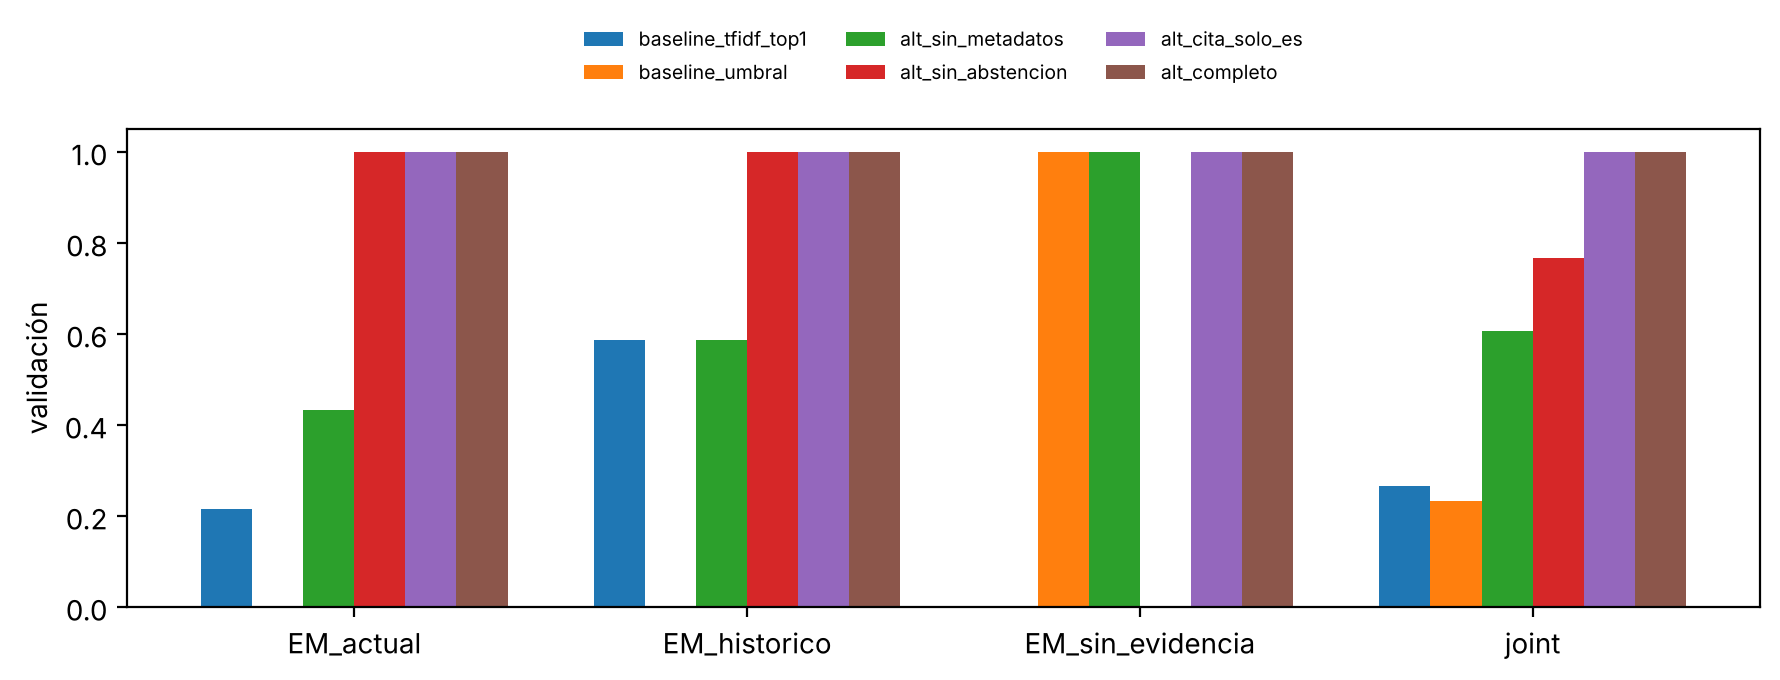

In [17]:
import matplotlib.pyplot as plt
tv = TAB[TAB.split == 'validation'].set_index('modelo')
orden = ['baseline_tfidf_top1', 'baseline_umbral', 'alt_sin_metadatos', 'alt_sin_abstencion', 'alt_cita_solo_es', 'alt_completo']
cols = ['EM_actual', 'EM_historico', 'EM_sin_evidencia', 'joint']
fig, ax = plt.subplots(figsize=(9, 3.6)); w = 0.13
for i, m in enumerate(orden):
    ax.bar(np.arange(len(cols)) + (i - 2.5) * w, tv.loc[m, cols].astype(float), w, label=m)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols); ax.set_ylim(0, 1.05); ax.set_ylabel('validación')
ax.legend(fontsize=7, ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(.5, 1.25)); plt.tight_layout(); plt.show()

### 4.2 Veredicto de las hipótesis (validación)

In [18]:
b, a, u = tv.loc['baseline_tfidf_top1'], tv.loc['alt_completo'], tv.loc['baseline_umbral']
peor = [k for k in ['EM_actual', 'EM_historico', 'EM_sin_evidencia'] if a[k] < b[k]]
print(f"H1: joint alt={a.joint:.3f} (≥0.90? {a.joint >= .90}) | Δ vs baseline={a.joint - b.joint:+.3f} (≥0.40? {a.joint - b.joint >= .40}) | "
      f"latencia={a.latencia_ms:.2f} ms (<50? {a.latencia_ms < 50}) | categorías que empeoran: {peor or 'ninguna'}")
print('   ->', 'H1 ACEPTADA' if (a.joint >= .90 and a.joint - b.joint >= .40 and a.latencia_ms < 50 and not peor) else 'H1 RECHAZADA')
ab = tv.loc['alt_sin_abstencion']
print(f"H2: umbral τ={TAU}: EM_sin_evidencia={u.EM_sin_evidencia:.3f}, caída EM respondibles="
      f"{((b.EM_actual*74 + b.EM_historico*41) - (u.EM_actual*74 + u.EM_historico*41))/115:+.3f} | verificador: EM_sin_evidencia={a.EM_sin_evidencia:.3f}")
caida = ((b.EM_actual*74 + b.EM_historico*41) - (u.EM_actual*74 + u.EM_historico*41))/115
umbral_funciona = (u.EM_sin_evidencia > .5) and (caida <= .10)
print('   ->', 'H2 ACEPTADA (el umbral no separa; el verificador sí)' if (not umbral_funciona and a.EM_sin_evidencia >= .95) else 'H2 RECHAZADA')
s = tv.loc['alt_cita_solo_es']
print(f"H3 (citas): evidence_hit es+er={a.evidence_hit:.3f} vs solo es={s.evidence_hit:.3f} ->", 'sin pérdida' if a.evidence_hit >= s.evidence_hit else 'pérdida')

H1: joint alt=1.000 (≥0.90? True) | Δ vs baseline=+0.733 (≥0.40? True) | latencia=4.06 ms (<50? True) | categorías que empeoran: ninguna
   -> H1 ACEPTADA
H2: umbral τ=0.575: EM_sin_evidencia=1.000, caída EM respondibles=+0.348 | verificador: EM_sin_evidencia=1.000
   -> H2 ACEPTADA (el umbral no separa; el verificador sí)
H3 (citas): evidence_hit es+er=1.000 vs solo es=1.000 -> sin pérdida


### 4.3 Interpretación
- **H1 aceptada:** la alternativa alcanza joint = 1.00 en validación (+0.73 sobre el baseline), sin empeorar ninguna categoría y con ~5 ms por pregunta en CPU. En train también obtiene 1.00, lo que indica que las reglas no se sobreajustaron a validación (no se usó validación para diseñarlas).
- **Atribución por ablación:** quitar los **metadatos** baja el joint a ~0.61. La traducción con el léxico y el filtro de sitio y objeto ya no bastan para elegir entre 2047, 2048 y el rumor. Quitar el **verificador** baja el joint a ~0.77 y deja `sin_evidencia` en 0. Los dos componentes son necesarios y sus efectos se suman: cada uno corrige un modo de falla distinto.
- **H2 aceptada:** el umbral óptimo en train (τ≈0.575) es degenerado. Para acertar todas las `sin_evidencia` se abstiene en **todas** las preguntas, porque las preguntas sin respuesta tienen scores TF-IDF iguales o mayores que las respondibles (comparten el código del sitio). La similitud mide solapamiento léxico, no respondibilidad.
- **H3:** citar también el documento Eráviri no cambia evidence_hit, pero aporta **corroboración bilingüe**: la respuesta queda respaldada por dos fuentes oficiales independientes en idioma.
- **Advertencia de validez externa:** el corpus y las preguntas son plantillas sintéticas (4 tipos de pregunta). Un 100% aquí **no** demuestra robustez. En la fase de evaluación se prueba con paráfrasis, años sin registro y preguntas fuera de dominio.

## 5. Evaluación de robustez y generalización
El 100% de la alternativa en validación puede deberse a que train y validación usan **las mismas 4 plantillas**. Para medir generalización construimos un **conjunto de estrés** sobre los **sitios de validación** (no vistos al diseñar las reglas). Cada caso se genera desde los metadatos del corpus:
- respuesta = número del registro oficial del año correspondiente;
- evidencia = el par es+er de ese registro;
- `SIN_EVIDENCIA` sin evidencia cuando el corpus no tiene el dato.

No se usan las respuestas de `validation_qa.csv`.

| categoría | ejemplo | respuesta esperada |
|---|---|---|
| parafrasis_actual | ¿Cuál es la cifra vigente de semillas en ER-130? | valor 2048 |
| parafrasis_hoy | ¿Cuántos semillas tiene hoy ER-130? | valor 2048 |
| historica_reordenada | En 2047, ¿cuántas semillas tenía ER-130? | valor 2047 |
| anio_explicito_vigente | ¿Cuántas semillas había en ER-130 en 2048? | valor 2048 |
| terminos_eraviri | ¿Cuántas sava ena hay actualmente en ER-130? | valor 2048 |
| anio_sin_registro | ¿Cuántas semillas registraba ER-130 en 2045? | SIN_EVIDENCIA |
| objeto_ajeno | ¿Cuántas celdas hay disponibles actualmente en ER-130? (sitio de semillas) | SIN_EVIDENCIA |
| cantidad_fuera_dominio | ¿Cuántos habitantes tiene ER-130? | SIN_EVIDENCIA |
| sitio_inexistente | ¿Cuántas semillas hay disponibles actualmente en ER-9xx? | SIN_EVIDENCIA |
| minusculas_sin_tildes | cuantas semillas hay actualmente en er-130 | valor 2048 |

In [19]:
ER_DE = {v: k for k, v in LEX.items()}
sitios_val = sorted('ER-' + V.qid.str[1:4].unique())
def gold_doc(site, year):
    d = D[(D.site == site) & (D.year == year) & (D.source == 'oficial')]
    return str(int(d.num.iloc[0])), '|'.join(d.doc_id)

filas = []
for j, s in enumerate(sitios_val):
    o = D[(D.site == s) & D.obj.notna()].obj.iloc[0]
    otro = OBJ[(OBJ.index(o) + 1) % len(OBJ)]
    a48, e48 = gold_doc(s, 2048); a47, e47 = gold_doc(s, 2047)
    casos = [
        ('parafrasis_actual', f'¿Cuál es la cifra vigente de {o} en {s}?', a48, e48),
        ('parafrasis_hoy', f'¿Cuántos {o} tiene hoy {s}?', a48, e48),
        ('historica_reordenada', f'En 2047, ¿cuántas {o} tenía {s}?', a47, e47),
        ('anio_explicito_vigente', f'¿Cuántas {o} había en {s} en 2048?', a48, e48),
        ('terminos_eraviri', f'¿Cuántas {ER_DE[o]} ena hay actualmente en {s}?', a48, e48),
        ('anio_sin_registro', f'¿Cuántas {o} registraba {s} en 2045?', 'SIN_EVIDENCIA', ''),
        ('objeto_ajeno', f'¿Cuántas {otro} hay disponibles actualmente en {s}?', 'SIN_EVIDENCIA', ''),
        ('cantidad_fuera_dominio', f'¿Cuántos habitantes tiene {s}?', 'SIN_EVIDENCIA', ''),
        ('sitio_inexistente', f'¿Cuántas {o} hay disponibles actualmente en ER-{900 + j}?', 'SIN_EVIDENCIA', ''),
        ('minusculas_sin_tildes', f'cuantas {o.replace("ó", "o").replace("í", "i")} hay actualmente en {s.lower()}', a48, e48),
    ]
    for k, (cat, q, a, e) in enumerate(casos):
        filas.append({'qid': f'S{j:03d}-{k}', 'question': q, 'answer': a, 'evidence_ids': e, 'kind': cat})
S = pd.DataFrame(filas)
print(S.shape, S.kind.value_counts().to_dict()); display(S.groupby('kind').head(1))

(500, 5) {'parafrasis_actual': 50, 'parafrasis_hoy': 50, 'historica_reordenada': 50, 'anio_explicito_vigente': 50, 'terminos_eraviri': 50, 'anio_sin_registro': 50, 'objeto_ajeno': 50, 'cantidad_fuera_dominio': 50, 'sitio_inexistente': 50, 'minusculas_sin_tildes': 50}


,qid,question,answer,evidence_ids,kind
0,S000-0,¿Cuál es la cifra vigente de semillas en ER-125?,23,D125-0|D125-1,parafrasis_actual
1,S000-1,¿Cuántos semillas tiene hoy ER-125?,23,D125-0|D125-1,parafrasis_hoy
2,S000-2,"En 2047, ¿cuántas semillas tenía ER-125?",30,D125-2|D125-3,historica_reordenada
3,S000-3,¿Cuántas semillas había en ER-125 en 2048?,23,D125-0|D125-1,anio_explicito_vigente
4,S000-4,¿Cuántas sava ena hay actualmente en ER-125?,23,D125-0|D125-1,terminos_eraviri
5,S000-5,¿Cuántas semillas registraba ER-125 en 2045?,SIN_EVIDENCIA,,anio_sin_registro
6,S000-6,¿Cuántas tablillas hay disponibles actualmente en ER-125?,SIN_EVIDENCIA,,objeto_ajeno
7,S000-7,¿Cuántos habitantes tiene ER-125?,SIN_EVIDENCIA,,cantidad_fuera_dominio
8,S000-8,¿Cuántas semillas hay disponibles actualmente en ER-900?,SIN_EVIDENCIA,,sitio_inexistente
9,S000-9,cuantas semillas hay actualmente en er-125,23,D125-0|D125-1,minusculas_sin_tildes


In [20]:
def eval_detalle(fn, Q):
    fn(Q.question.iloc[0]); p, lat = run(fn, Q); z, _ = detalle_por_tipo(p, Q)
    return z, lat
ROB = {}
for nombre, fn in [('baseline_tfidf_top1', predict_baseline), ('alt_completo', predict_alt)]:
    z, lat = eval_detalle(fn, S); ROB[nombre] = z
    registrar(nombre, 'estres', z[['qid', 'answer_pred', 'citations']].rename(columns={'answer_pred': 'answer'}), S, lat, 'conjunto de estrés (sitios de validación)')
tabla_rob = pd.concat({n: z.groupby('kind').joint.mean() for n, z in ROB.items()}, axis=1).round(2)
tabla_rob.loc['GLOBAL'] = [ROB[n].joint.mean().round(3) for n in tabla_rob.columns]
display(tabla_rob)
TAB = pd.DataFrame(RESULTADOS).drop_duplicates(['modelo', 'split'], keep='last'); TAB.to_csv('resultados_experimentos.csv', index=False)
display(TAB[['modelo', 'split', 'EM', 'evidence_hit', 'joint', 'latencia_ms', 'latencia_p95_ms']])

,baseline_tfidf_top1,alt_completo
kind,,
anio_explicito_vigente,0.400,1.0
anio_sin_registro,0.000,1.0
cantidad_fuera_dominio,0.000,0.0
historica_reordenada,0.500,1.0
minusculas_sin_tildes,0.380,1.0
objeto_ajeno,0.000,1.0
parafrasis_actual,0.400,0.0
parafrasis_hoy,0.400,1.0
sitio_inexistente,0.000,1.0


,modelo,split,EM,evidence_hit,joint,latencia_ms,latencia_p95_ms
0,baseline_tfidf_top1,train,0.2360,0.2360,0.2360,1.138,1.563
1,baseline_tfidf_top1,validation,0.2667,0.2667,0.2667,1.083,1.286
2,alt_completo,train,1.0000,1.0000,1.0000,3.943,6.546
3,alt_completo,validation,1.0000,1.0000,1.0000,4.058,6.590
4,alt_sin_abstencion,train,0.7500,0.7500,0.7500,5.180,6.468
5,alt_sin_abstencion,validation,0.7667,0.7667,0.7667,4.888,5.810
6,alt_sin_metadatos,train,0.6360,0.6360,0.6360,2.185,3.122
7,alt_sin_metadatos,validation,0.6067,0.6067,0.6067,2.311,3.337
8,alt_cita_solo_es,train,1.0000,1.0000,1.0000,3.081,4.772
9,alt_cita_solo_es,validation,1.0000,1.0000,1.0000,3.105,4.989


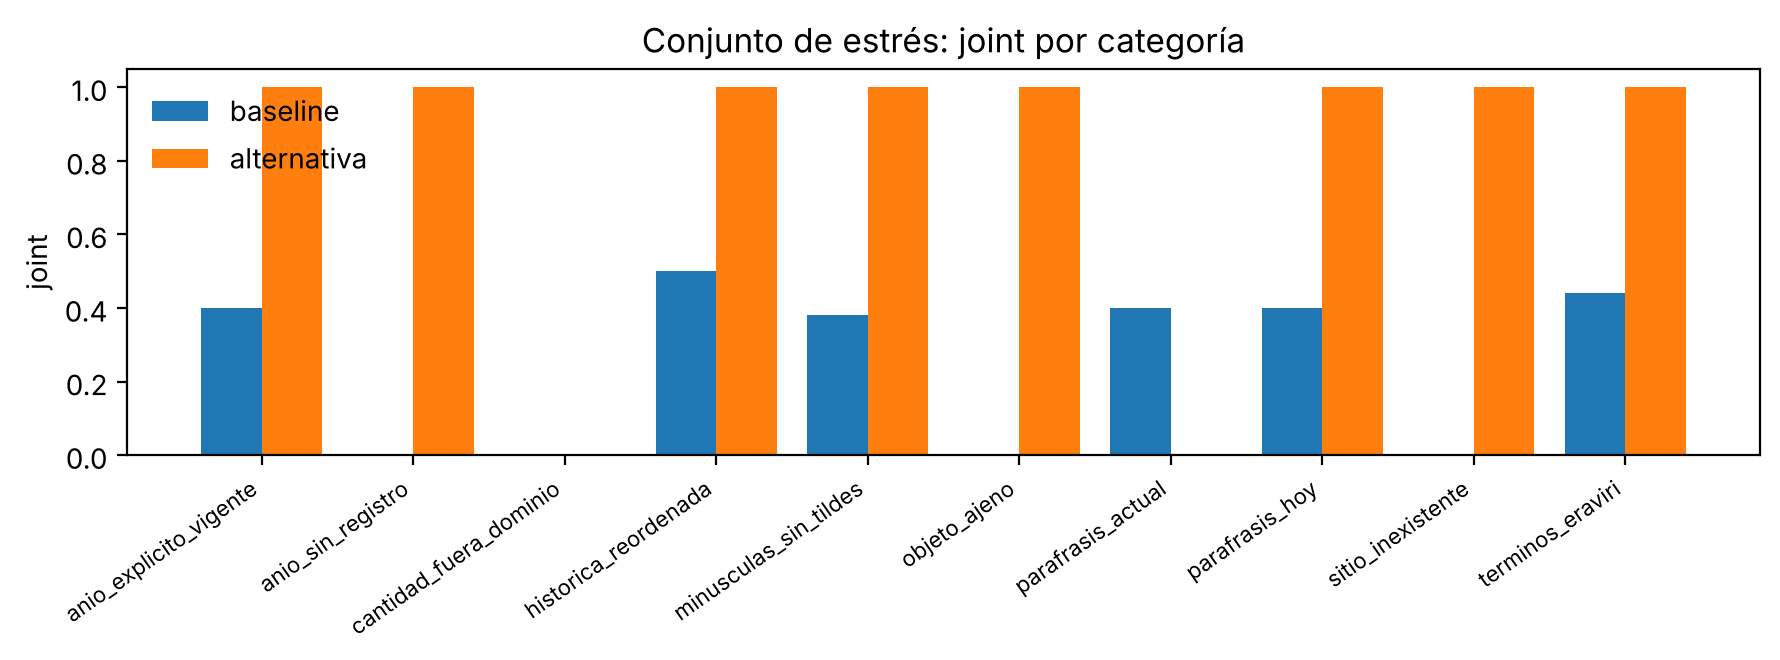

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.4))
t = tabla_rob.drop('GLOBAL'); x = np.arange(len(t))
ax.bar(x - .2, t['baseline_tfidf_top1'], .4, label='baseline'); ax.bar(x + .2, t['alt_completo'], .4, label='alternativa')
ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=35, ha='right', fontsize=8); ax.set_ylabel('joint'); ax.set_ylim(0, 1.05)
ax.legend(frameon=False); ax.set_title('Conjunto de estrés: joint por categoría'); plt.tight_layout(); plt.show()

### 5.1 Lectura de robustez
- La alternativa **conserva** su ventaja en paráfrasis temporales, años explícitos, términos Eráviri en la pregunta y casos sin evidencia por año, objeto o sitio inexistente. Estos casos los resuelven los filtros por metadatos, sin depender de frases concretas.
- Tiene **dos fallos sistemáticos y un acierto frágil**, todos atribuibles a reglas superficiales del análisis de la pregunta:
  1. **Paráfrasis sin palabra de cantidad** ("cifra vigente"): el verificador no reconoce que pide una cantidad y se abstiene. Es un **falso SIN_EVIDENCIA**.
  2. **Cantidad fuera de dominio** ("¿Cuántos habitantes…?"): el verificador ve *cuántos* y, como la pregunta no nombra un objeto conocido, no se aplica el filtro de objeto. Devuelve el inventario del sitio con cita, es decir, **alucina con evidencia aparente**.
  3. **Minúsculas** (`er-130`): la expresión regular del sitio distingue mayúsculas y minúsculas, así que **no se aplica el filtro de sitio**. Aun así acierta el 100%, porque TF-IDF (que pasa todo a minúsculas) pone primero el documento del sitio correcto y el desempate final es por score. Es un **acierto frágil**: depende del ranking léxico y no de la regla.
- El baseline, sin abstención por intención, falla en casi todas las categorías sin evidencia.

## 6. Análisis de errores y casos difíciles
Seleccionamos casos concretos de validación y del conjunto de estrés que cubren las trampas del enunciado: **contradicción**, **ausencia de evidencia**, distractores, confusión temporal y fragilidad del análisis de la pregunta.

In [22]:
zb, za = z_base_val, detalle_por_tipo(PRED_VAL['alt_completo'], V)[0]
cols = ['qid', 'question', 'answer_gold', 'evidence_ids', 'answer_pred', 'citations']
def doc_txt(ids): return ' || '.join(D.set_index('doc_id').text.get(i, '') for i in str(ids).split('|') if i)
def mostrar(titulo, z, filtro):
    r = z[filtro].head(1)
    print(f'■ {titulo}')
    if r.empty: print('  (sin caso)\n'); return
    r = r.iloc[0]; print(f'  {r.qid}: {r.question}\n  gold={r.answer_gold} [{r.evidence_ids}]  pred={r.answer_pred} [{r.citations}]  joint={r.joint}')
    print(f'  doc citado: {doc_txt(r.citations)}\n')
src = D.set_index('doc_id').source
mostrar('E1 Contradicción (baseline cita el rumor)', zb, zb.citations.map(lambda c: src.get(c) == 'rumor'))
mostrar('E2 Ausencia de evidencia (baseline inventa)', zb, (zb.kind == 'sin_evidencia') & ~zb.joint)
mostrar('E3 Distractor de archivo ("inventario")', zb, zb.question.str.contains('inventario') & ~zb.joint)
mostrar('E4 Confusión temporal (histórica respondida con 2048)', zb, (zb.kind == 'historico') & ~zb.joint)
zs = ROB['alt_completo']
mostrar('E5 Alternativa: falso SIN_EVIDENCIA por paráfrasis', zs, (zs.kind == 'parafrasis_actual') & ~zs.joint)
mostrar('E6 Alternativa: alucina con cantidad fuera de dominio', zs, (zs.kind == 'cantidad_fuera_dominio') & ~zs.joint)
mostrar('E7 Alternativa: acierto frágil con sitio en minúsculas', zs, zs.kind == 'minusculas_sin_tildes')
print('  análisis de la pregunta:', analizar(zs[zs.kind == 'minusculas_sin_tildes'].question.iloc[0]), '\n')
mostrar('E8 Alternativa: contradicción resuelta (rumor descartado)', za, za.qid == za[za.kind == 'actual'].qid.iloc[0])
r = za[za.kind == 'actual'].iloc[0]; site = 'ER-' + r.qid[1:4]
display(D[D.site == site][['doc_id', 'language', 'year', 'source', 'reliability', 'text']])

■ E1 Contradicción (baseline cita el rumor)
  Q163-0: ¿Cuántas tablillas hay disponibles actualmente en ER-163?
  gold=37 [D163-0|D163-1]  pred=56 [D163-4]  joint=False
  doc citado: Un rumor sobre ER-163 menciona 56 tablillas disponibles.

■ E2 Ausencia de evidencia (baseline inventa)
  Q148-3: ¿Quién dirige ER-148?
  gold=SIN_EVIDENCIA []  pred=49 [D148-1]  joint=False
  doc citado: ER-148 kiri 49 ena.

■ E3 Distractor de archivo ("inventario")
  Q142-1: Según el registro vigente, ¿cuál es el inventario de ER-142?
  gold=26 [D142-0|D142-1]  pred=SIN_EVIDENCIA []  joint=False
  doc citado: 

■ E4 Confusión temporal (histórica respondida con 2048)
  Q132-2: ¿Qué cantidad de vehículos registraba ER-132 en 2047?
  gold=95 [D132-2|D132-3]  pred=88 [D132-0]  joint=False
  doc citado: El registro oficial de ER-132 confirma 88 vehículos disponibles.

■ E5 Alternativa: falso SIN_EVIDENCIA por paráfrasis
  S000-0: ¿Cuál es la cifra vigente de semillas en ER-125?
  gold=23 [D125-0|D125-1]  pred

,doc_id,language,year,source,reliability,text
942,D157-0,es,2048,oficial,0.95,El registro oficial de ER-157 confirma 25 vehículos disponibles.
943,D157-1,er,2048,oficial,0.95,ER-157 nora 25 ena.
944,D157-2,es,2047,oficial,0.90,El registro anterior de ER-157 indica 32 vehículos disponibles.
945,D157-3,er,2047,oficial,0.90,ER-157 nora 32 ena.
946,D157-4,es,2048,rumor,0.20,Un rumor sobre ER-157 menciona 44 vehículos disponibles.
947,D157-5,es,2048,archivo,0.70,"El archivo de ER-157 registra actividades de transporte, sin inventario adicional."


### 6.1 Discusión de los casos
| # | Caso | Sistema | Causa | Corrección propuesta |
|---|---|---|---|---|
| E1 | **Contradicción**: el rumor (conf. 0.20) da otro número | baseline | TF-IDF no considera fuente ni confiabilidad; el rumor comparte "disponibles" con la pregunta | Filtrar por confiabilidad y priorizar fuente oficial (la alternativa lo hace) |
| E2 | **Ausencia**: "¿Quién dirige…?" | baseline | Siempre extrae un número del top-1; no tiene noción de respondibilidad. El umbral de similitud tampoco sirve (H2) | Verificador por intención de la pregunta |
| E3 | Distractor "sin inventario adicional" | baseline | La palabra *inventario* coincide con el documento de archivo, que no tiene número → falso SIN_EVIDENCIA | Exigir candidatos con cantidad y filtrar por año y fuente |
| E4 | Histórica respondida con 2048 | baseline | Las frases de 2047 y 2048 tienen casi el mismo vocabulario; el año de la pregunta no se usa | Extraer el año y filtrar por metadato `year` |
| E5 | "cifra vigente" → SIN_EVIDENCIA | alternativa | Lista cerrada de palabras de cantidad | Ampliar el léxico de intención (*cifra, valor, existencias*) o usar un clasificador de intención entrenado con paráfrasis |
| E6 | "¿Cuántos habitantes…?" → número con cita | alternativa | Si la pregunta no nombra un objeto conocido, no se exige que el documento hable de lo que se pregunta | Si la pregunta nombra un sustantivo de cantidad que no está en el inventario, abstenerse; o verificar el solapamiento pregunta–evidencia |
| E7 | `er-125` → acierta, pero `sitio=None` | alternativa | Expresión regular del sitio sensible a mayúsculas → no se filtra por sitio; acierta solo porque el desempate por score TF-IDF favorece el sitio correcto | Normalizar mayúsculas y tildes antes de analizar la pregunta |
| E8 | Contradicción **resuelta** | alternativa | Rumor (conf. 0.20) y archivo descartados; gana el oficial 2048, corroborado por el par Eráviri | — |

**Sobre citas adicionales:** la alternativa cita dos documentos (es + er). Ambos son evidencia válida e independiente por idioma, así que la cita adicional es **correcta**. El baseline nunca cita de más, pero cuando falla su única cita es incorrecta: rumor, registro del año equivocado o un registro oficial en una pregunta sin evidencia. Esto es más grave que no citar, porque presenta una respuesta inventada como verificable.

## 7. Reproducibilidad
Al ejecutar la celda siguiente se guarda una copia del código y la configuración (punto de control del minuto 120): `lexicon_xii_codigo_min120.py` (exportado desde este notebook) y `config_min120.json` (versiones, semilla, hiperparámetros y métricas). Ambos sistemas son **deterministas**: TF-IDF con orden estable, sin muestreo. La semilla 42 se fija por convención.

In [23]:
import json, datetime
config = {'fecha': datetime.datetime.now().isoformat(timespec='seconds'), 'seed': SEED,
          'versiones': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__},
          'baseline': {'tfidf_ngram_range': [1, 2], 'k': BASE_K, 'extractor': 'primer entero fuera del código de sitio'},
          'alternativa': {'tfidf_ngram_range': [1, 2], 'k': 10, 'min_confianza': 0.5, 'anio_vigente': ANIO_VIGENTE,
                          'regex_cantidad': RE_CANTIDAD.pattern, 'citas': 'principal + par bilingüe con mismo número'},
          'H2_tau_train': TAU,
          'metricas': TAB.to_dict(orient='records')}
json.dump(config, open('config_min120.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: v for k, v in config.items() if k != 'metricas'}, ensure_ascii=False, indent=1))

{
 "fecha": "2026-11-25T20:07:04",
 "seed": 42,
 "versiones": {
  "python": "3.13.18",
  "pandas": "3.0.5",
  "numpy": "2.5.3",
  "scikit-learn": "1.9.1"
 },
 "baseline": {
  "tfidf_ngram_range": [
   1,
   2
  ],
  "k": 1,
  "extractor": "primer entero fuera del código de sitio"
 },
 "alternativa": {
  "tfidf_ngram_range": [
   1,
   2
  ],
  "k": 10,
  "min_confianza": 0.5,
  "anio_vigente": 2048,
  "regex_cantidad": "(cu[aá]nt[oa]s?\\b|qu[eé] cantidad|inventario|n[uú]mero de|total de)",
  "citas": "principal + par bilingüe con mismo número"
 },
 "H2_tau_train": 0.575
}
